Using Colab cache for faster access to the 'deepglobe-road-extraction-dataset' dataset.
Using Colab cache for faster access to the 'deepglobe-land-cover-classification-dataset' dataset.
gdown failed: Failed to retrieve file url:

	Cannot retrieve the public link of the file. You may need to change
	
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
using zip from Drive: /content/drive/MyDrive/data_original_size_v1.zip
roads: 6226 | urban: 803 | ttpla: 1242
roads: train (400, 256), test (200, 256)
urban: train (400, 256), test (200, 256)
wires: train (400, 8), test (200, 8)

=== roads ===
    step   0 loss 0.689
    step  25 loss 0.632
    step  50 loss 0.676
    step  75 loss 0.652
  8q seed 0: acc 0.630
  8q seed 1: acc 0.590
  8q seed 2: acc 0.655
  4q mean acc 0.625
  noise: {'task': 'roads', 'noise 0.0': np.float64(0.65), 'noise 0.01': np.float64(0.65), 'noise 0.03': np.float64(0.625), 'noise 0.05': np.f

,task,QCNN acc (mean±std),LogReg,MLP,QCNN params,MLP params,acc on confident 80%
0,roads,0.625±0.027,0.605,0.605,21,161,0.650
1,urban,0.625±0.007,0.620,0.570,21,161,0.669
2,wires,0.595±0.014,0.545,0.690,21,161,0.612


##### ABLATION: 4 vs 8 qubits


,task,4 qubits,8 qubits
0,roads,0.625±0.033,0.625±0.027
1,urban,0.593±0.015,0.625±0.007
2,wires,0.585±0.004,0.595±0.014


##### NOISE: accuracy vs depolarizing noise


,task,noise 0.0,noise 0.01,noise 0.03,noise 0.05
0,roads,0.650,0.650,0.625,0.60
1,urban,0.675,0.675,0.675,0.65
2,wires,0.550,0.550,0.550,0.55


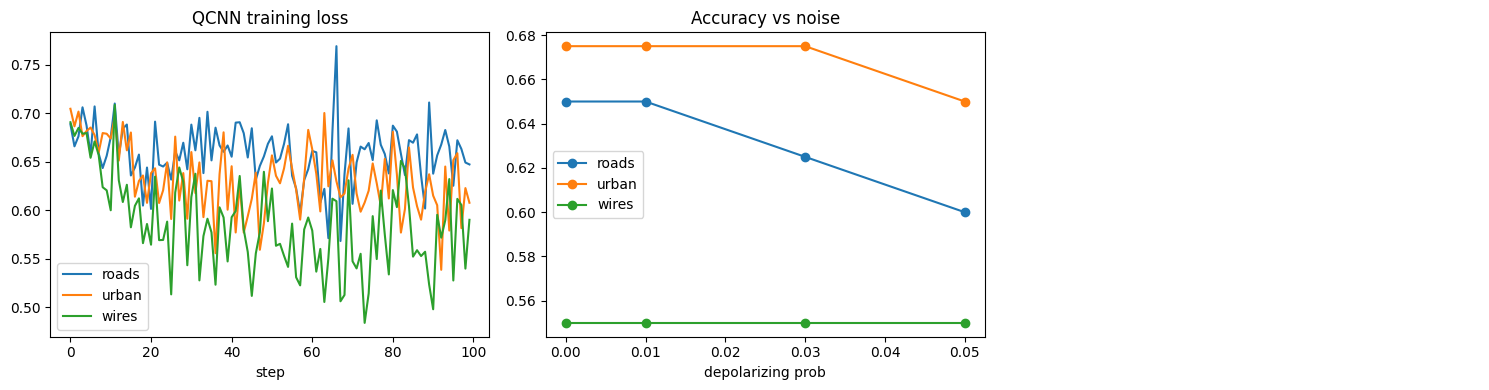

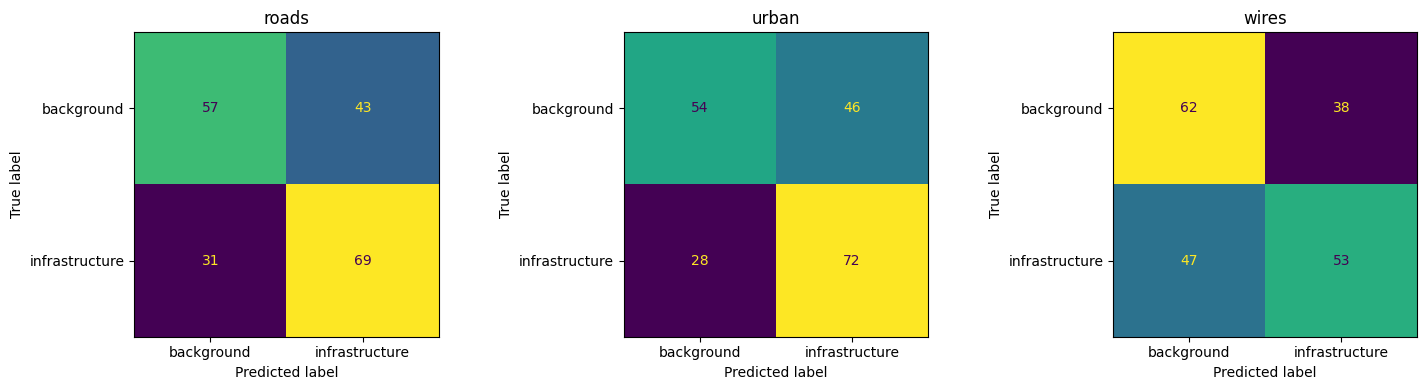

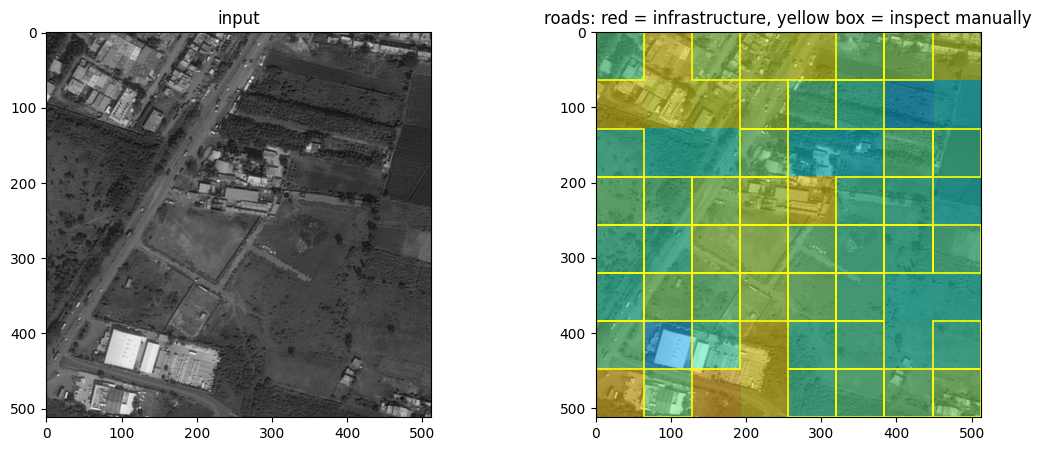

patches: 64 | predicted infrastructure: 24 | flagged for manual check: 41


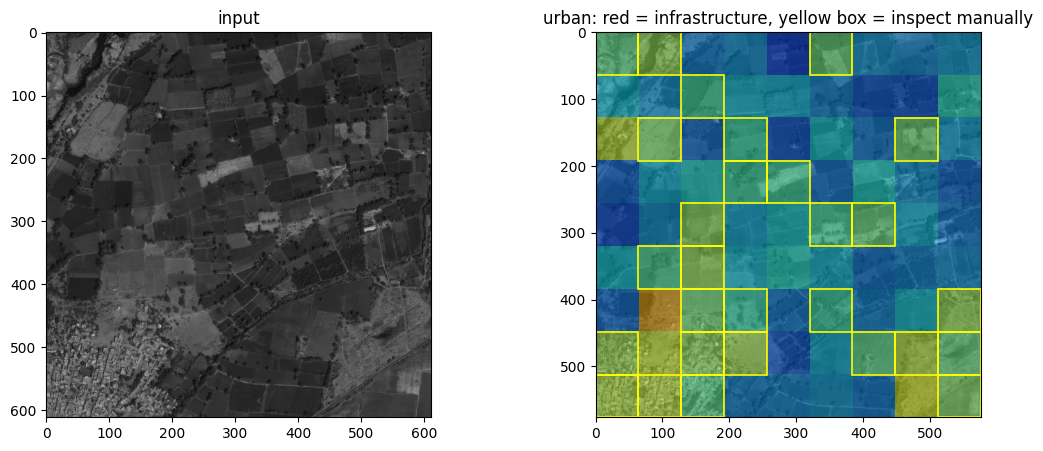

patches: 81 | predicted infrastructure: 16 | flagged for manual check: 28


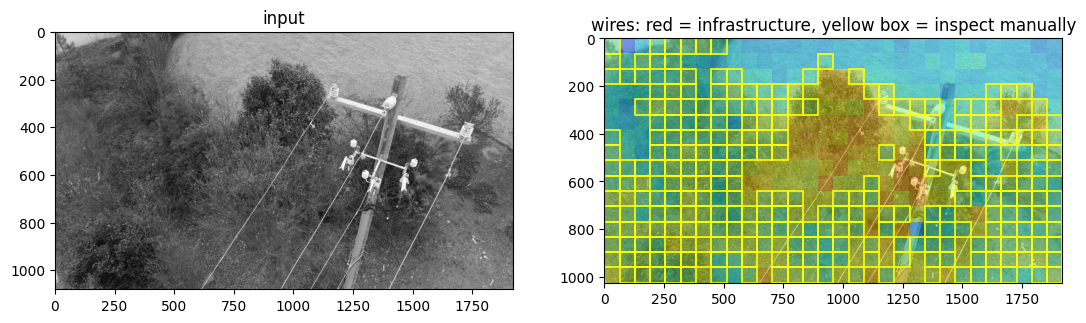

patches: 480 | predicted infrastructure: 233 | flagged for manual check: 269


In [19]:
!pip install pennylane kagglehub gdown -q

import kagglehub, gdown, glob, os, zipfile, json
import numpy as np
from PIL import Image, ImageDraw

SEEDS, STEPS = 3, 100          # lower these (e.g. 1 and 60) for a quick test run

# ============ 1. DOWNLOAD DATA ============
road = kagglehub.dataset_download("balraj98/deepglobe-road-extraction-dataset")
land = kagglehub.dataset_download("balraj98/deepglobe-land-cover-classification-dataset")

ZIP = "ttpla_subset.zip"
def ok(p): return os.path.exists(p) and zipfile.is_zipfile(p)
if not ok(ZIP):
    try: gdown.download(id="1VHtu_ndp3arjMpyeAMtegSCux_21Qp7N", output=ZIP, quiet=False)
    except Exception as e: print("gdown failed:", str(e)[:100])
if not ok(ZIP):
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        for c in glob.glob("/content/drive/MyDrive/*.zip") + glob.glob("/content/drive/MyDrive/*/*.zip"):
            try:
                with zipfile.ZipFile(c) as z: names = z.namelist()
                if any(n.lower().endswith(".json") for n in names) and any(n.lower().endswith(".jpg") for n in names):
                    print("using zip from Drive:", c); ZIP = c; break
            except Exception: pass
    except Exception as e: print("Drive step failed:", str(e)[:100])
os.makedirs("/content/ttpla", exist_ok=True)
if ok(ZIP):
    with zipfile.ZipFile(ZIP) as z: z.extractall("/content/ttpla")
else:
    print("!! TTPLA zip not available -> wires task skipped")

road_files = [f for f in sorted(glob.glob(f"{road}/**/*_sat.jpg", recursive=True))
              if os.path.exists(f.replace("_sat.jpg", "_mask.png"))]
land_files = [f for f in sorted(glob.glob(f"{land}/**/*_sat.jpg", recursive=True))
              if os.path.exists(f.replace("_sat.jpg", "_mask.png"))]
tt_files = [f for f in sorted(glob.glob("/content/ttpla/**/*", recursive=True))
            if f.lower().endswith((".jpg", ".jpeg")) and os.path.exists(os.path.splitext(f)[0] + ".json")]
print("roads:", len(road_files), "| urban:", len(land_files), "| ttpla:", len(tt_files))

# ============ 2. LOADERS + FEATURES + PATCHES ============
def load_road(sat):
    g = Image.open(sat).convert("L").resize((512, 512))
    m = Image.open(sat.replace("_sat.jpg", "_mask.png")).convert("L").resize((512, 512), Image.NEAREST)
    return np.array(g), np.array(m) > 127

def load_urban(sat):                     # urban = cyan (0,255,255)
    g = Image.open(sat).convert("L").resize((612, 612))
    m = np.array(Image.open(sat.replace("_sat.jpg", "_mask.png")).convert("RGB").resize((612, 612), Image.NEAREST))
    return np.array(g), (m[..., 0] < 128) & (m[..., 1] > 128) & (m[..., 2] > 128)

def load_ttpla(jpg, scale=2):
    meta = json.load(open(os.path.splitext(jpg)[0] + ".json"))
    img = Image.open(jpg).convert("L"); W, H = img.size
    img = img.resize((W // scale, H // scale))
    mk = Image.new("L", img.size, 0); d = ImageDraw.Draw(mk)
    for s in meta["shapes"]:
        if "cable" in s["label"].lower() and len(s["points"]) >= 3:
            d.polygon([(x / scale, y / scale) for x, y in s["points"]], fill=1)
    return np.array(img), np.array(mk) > 0

def feat_vec(p, feat):
    p = p.astype(np.float32) / 255.0
    if feat == "orient":                 # edge-direction histogram: suits thin lines (8 values)
        gy, gx = np.gradient(p); mag = np.hypot(gx, gy)
        ang = np.arctan2(gy, gx) % np.pi
        h, _ = np.histogram(ang, bins=7, range=(0, np.pi), weights=mag)
        return np.append(h / (h.sum() + 1e-6), min(mag.mean() * 10, 1.0))
    small = Image.fromarray((p * 255).astype(np.uint8)).resize((16, 16), Image.BOX)
    return (np.array(small) / 255.0).ravel()

def patches_from_files(files, loader, patch, thr, feat):
    pos, neg = [], []
    for f in files:
        g, m = loader(f)
        for y in range(0, g.shape[0] - patch + 1, patch):
            for x in range(0, g.shape[1] - patch + 1, patch):
                frac = m[y:y+patch, x:x+patch].mean()
                if frac >= thr:  pos.append(feat_vec(g[y:y+patch, x:x+patch], feat))
                elif frac == 0:  neg.append(feat_vec(g[y:y+patch, x:x+patch], feat))
    return pos, neg

def balance(pos, neg, n, rng):
    n = min(n, len(pos), len(neg))
    if n == 0: return None, None
    pi = rng.choice(len(pos), n, replace=False); ni = rng.choice(len(neg), n, replace=False)
    X = np.array([pos[i] for i in pi] + [neg[i] for i in ni]); y = np.array([1]*n + [0]*n)
    k = rng.permutation(len(X)); return X[k], y[k]

def make_dataset(files, loader, patch, thr, feat, n_tr=200, n_te=100, seed=0):
    rng = np.random.default_rng(seed)             # split BY IMAGE (no leakage)
    files = list(files); rng.shuffle(files)
    k = max(1, int(0.75 * len(files)))
    Xtr, ytr = balance(*patches_from_files(files[:k], loader, patch, thr, feat), n_tr, rng)
    Xte, yte = balance(*patches_from_files(files[k:], loader, patch, thr, feat), n_te, rng)
    return Xtr, ytr, Xte, yte

# ============ 3. BUILD THE 3 DATASETS ============
CFG = {
  "roads": dict(files=road_files[:40],  loader=load_road,  patch=64, thr=0.05, feat="raw"),
  "urban": dict(files=land_files[:150], loader=load_urban, patch=64, thr=0.50, feat="raw"),
  "wires": dict(files=tt_files[::20],   loader=load_ttpla, patch=64, thr=0.02, feat="orient"),
}
RAW = {}
for name, c in CFG.items():
    if len(c["files"]) < 2: print(f"[skip] {name}: not enough files"); continue
    out = make_dataset(**c)
    if out[0] is None or out[2] is None: print(f"[skip] {name}: missing a class"); continue
    RAW[name] = out
    print(f"{name}: train {out[0].shape}, test {out[2].shape}")

# ============ 4. QCNN (any qubit count, optional noise) ============
import torch, pennylane as qml

def conv(p, a, b):
    qml.RY(p[0], wires=a); qml.RY(p[1], wires=b)
    qml.CNOT(wires=[a, b]); qml.RZ(p[2], wires=b); qml.CNOT(wires=[b, a])
    qml.RY(p[3], wires=a); qml.RY(p[4], wires=b)

def pool(p, a, b):                        # a discarded, b kept
    qml.CRZ(p[0], wires=[a, b]); qml.PauliX(wires=a); qml.CRX(p[1], wires=[a, b])

_cache = {}
def get_qnode(n, noise=0.0):
    key = (n, noise)
    if key in _cache: return _cache[key]
    dev = qml.device("default.mixed" if noise > 0 else "default.qubit", wires=n)
    def nz(ws):
        if noise > 0:
            for q in ws: qml.DepolarizingChannel(noise, wires=q)
    @qml.qnode(dev, interface="torch")
    def circuit(x, w, pw):
        qml.AngleEmbedding(x, wires=range(n), rotation="Y")       # angle encoding
        wires, l = list(range(n)), 0
        while len(wires) > 1:
            for i in range(0, len(wires) - 1, 2): conv(w[l], wires[i], wires[i+1]); nz([wires[i], wires[i+1]])
            for i in range(0, len(wires) - 1, 2): pool(pw[l], wires[i], wires[i+1]); nz([wires[i], wires[i+1]])
            wires = wires[1::2]; l += 1
        return qml.expval(qml.PauliZ(wires[0]))
    _cache[key] = circuit; return circuit

def predict_prob(circ, X, w, pw):
    with torch.no_grad():
        return ((circ(X, w, pw) + 1) / 2).numpy()

def train_qcnn(n, Xtr, ytr, Xte, steps=STEPS, bs=64, lr=0.05, seed=0, verbose=False):
    torch.manual_seed(seed); L = int(np.log2(n)); circ = get_qnode(n)
    w  = (0.5 * torch.randn(L, 5, dtype=torch.float64)).requires_grad_()
    pw = (0.5 * torch.randn(L, 2, dtype=torch.float64)).requires_grad_()
    opt = torch.optim.Adam([w, pw], lr=lr)
    Xt = torch.tensor(Xtr, dtype=torch.float64); yt = torch.tensor(ytr, dtype=torch.float64)
    hist = []
    for s in range(steps):
        idx = torch.randperm(len(Xt))[:bs]
        prob = ((circ(Xt[idx], w, pw) + 1) / 2).clamp(1e-5, 1 - 1e-5)
        loss = torch.nn.functional.binary_cross_entropy(prob, yt[idx])
        opt.zero_grad(); loss.backward(); opt.step(); hist.append(loss.item())
        if verbose and s % 25 == 0: print(f"    step {s:3d} loss {loss.item():.3f}")
    w, pw = w.detach(), pw.detach()
    pte = predict_prob(circ, torch.tensor(Xte, dtype=torch.float64), w, pw)
    return pte, w, pw, hist, w.numel() + pw.numel()

def eval_noisy(n, Xte, yte, w, pw, p, m=40):
    circ = get_qnode(n, p); m = min(m, len(Xte)); probs = []
    with torch.no_grad():
        for i in range(m):
            probs.append(((circ(torch.tensor(Xte[i], dtype=torch.float64), w, pw) + 1) / 2).item())
    return ((np.array(probs) > 0.5) == yte[:m]).mean()

# ============ 5. RUN EVERYTHING ============
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def prep(k, Xtr, Xte):
    pca = PCA(k).fit(Xtr)                                        # fit on TRAIN only
    sc = MinMaxScaler((0, np.pi)).fit(pca.transform(Xtr))
    f = lambda X: np.clip(sc.transform(pca.transform(X)), 0, np.pi)
    return pca, sc, f(Xtr), f(Xte)

MODELS, main_rows, abl_rows, noise_rows, curves, cms = {}, [], [], [], {}, {}
NOISE = [0.0, 0.01, 0.03, 0.05]

for name, (Xtr, ytr, Xte, yte) in RAW.items():
    print(f"\n=== {name} ===")
    # ---- 8 qubits (main) ----
    pca8, sc8, Ftr, Fte = prep(8, Xtr, Xte)
    runs = []
    for seed in range(SEEDS):
        pte, w, pw, hist, npar = train_qcnn(8, Ftr, ytr, Fte, seed=seed, verbose=(seed == 0))
        runs.append((((pte > 0.5) == yte).mean(), pte, w, pw, hist))
        print(f"  8q seed {seed}: acc {runs[-1][0]:.3f}")
    accs8 = [r[0] for r in runs]
    _, pte0, w0, pw0, hist0 = runs[0]                  # seed 0 used downstream (no cherry-picking)
    curves[name] = hist0
    cms[name] = confusion_matrix(yte, (pte0 > 0.5).astype(int))
    MODELS[name] = dict(pca=pca8, sc=sc8, w=w0, pw=pw0, feat=CFG[name]["feat"], patch=CFG[name]["patch"])

    lr_acc = LogisticRegression(max_iter=1000).fit(Ftr, ytr).score(Fte, yte)
    mlp_acc = MLPClassifier((16,), max_iter=2000, random_state=0).fit(Ftr, ytr).score(Fte, yte)

    conf = np.abs(pte0 - 0.5); flag = conf <= np.quantile(conf, 0.20)      # least-confident 20% -> manual check
    conf_acc = ((pte0[~flag] > 0.5) == yte[~flag]).mean()
    main_rows.append({"task": name, "QCNN acc (mean±std)": f"{np.mean(accs8):.3f}±{np.std(accs8):.3f}",
                      "LogReg": round(lr_acc, 3), "MLP": round(mlp_acc, 3), "QCNN params": npar,
                      "MLP params": 161, "acc on confident 80%": round(conf_acc, 3)})

    # ---- 4 qubits (ablation) ----
    _, _, Ftr4, Fte4 = prep(4, Xtr, Xte)
    accs4 = []
    for seed in range(SEEDS):
        pte4, *_ = train_qcnn(4, Ftr4, ytr, Fte4, seed=seed)
        accs4.append(((pte4 > 0.5) == yte).mean())
    abl_rows.append({"task": name, "4 qubits": f"{np.mean(accs4):.3f}±{np.std(accs4):.3f}",
                     "8 qubits": f"{np.mean(accs8):.3f}±{np.std(accs8):.3f}"})
    print(f"  4q mean acc {np.mean(accs4):.3f}")

    # ---- noise test (trained 8q weights, evaluated under depolarizing noise) ----
    row = {"task": name}
    for p in NOISE: row[f"noise {p}"] = round(eval_noisy(8, Fte, yte, w0, pw0, p), 3)
    noise_rows.append(row); print("  noise:", row)

print("\n##### MAIN RESULTS (QCNN vs classical)");  display(pd.DataFrame(main_rows))
print("##### ABLATION: 4 vs 8 qubits");             display(pd.DataFrame(abl_rows))
print("##### NOISE: accuracy vs depolarizing noise"); display(pd.DataFrame(noise_rows))
pd.DataFrame(main_rows).to_csv("results_main.csv", index=False)
pd.DataFrame(abl_rows).to_csv("results_ablation.csv", index=False)
pd.DataFrame(noise_rows).to_csv("results_noise.csv", index=False)

# ---- plots ----
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for k, h in curves.items(): ax[0].plot(h, label=k)
ax[0].set_title("QCNN training loss"); ax[0].set_xlabel("step"); ax[0].legend()
for r in noise_rows: ax[1].plot(NOISE, [r[f"noise {p}"] for p in NOISE], marker="o", label=r["task"])
ax[1].set_title("Accuracy vs noise"); ax[1].set_xlabel("depolarizing prob"); ax[1].legend()
ax[2].axis("off"); plt.tight_layout(); plt.savefig("loss_noise.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, len(cms), figsize=(5 * len(cms), 4))
ax = np.atleast_1d(ax)
for a, (k, cm) in zip(ax, cms.items()):
    ConfusionMatrixDisplay(cm, display_labels=["background", "infrastructure"]).plot(ax=a, colorbar=False)
    a.set_title(k)
plt.tight_layout(); plt.savefig("confusion.png", dpi=150); plt.show()

# ============ 6. DEMO: upload-style prediction with confidence ============
def load_gray(path, task):
    img = Image.open(path).convert("L")
    if task == "roads": return np.array(img.resize((512, 512)))
    if task == "urban": return np.array(img.resize((612, 612)))
    W, H = img.size; return np.array(img.resize((W // 2, H // 2)))

def demo(path, task, band=0.1):
    M = MODELS[task]; g = load_gray(path, task); P = M["patch"]
    ys = list(range(0, g.shape[0] - P + 1, P)); xs = list(range(0, g.shape[1] - P + 1, P))
    feats = np.array([feat_vec(g[y:y+P, x:x+P], M["feat"]) for y in ys for x in xs])
    F = np.clip(M["sc"].transform(M["pca"].transform(feats)), 0, np.pi)
    p = predict_prob(get_qnode(8), torch.tensor(F, dtype=torch.float64), M["w"], M["pw"])
    grid = p.reshape(len(ys), len(xs)); unsure = np.abs(grid - 0.5) < band
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    ax[0].imshow(g, cmap="gray"); ax[0].set_title("input")
    ax[1].imshow(g, cmap="gray")
    ax[1].imshow(grid, extent=(0, len(xs)*P, len(ys)*P, 0), alpha=0.45, cmap="jet", vmin=0, vmax=1, interpolation="nearest")
    for i, j in zip(*np.where(unsure)):
        ax[1].add_patch(plt.Rectangle((j*P, i*P), P, P, fill=False, edgecolor="yellow", lw=1.2))
    ax[1].set_title(f"{task}: red = infrastructure, yellow box = inspect manually")
    plt.show()
    print(f"patches: {grid.size} | predicted infrastructure: {(grid > 0.5).sum()} | flagged for manual check: {unsure.sum()}")

if "roads" in MODELS: demo(road_files[100], "roads")
if "urban" in MODELS: demo(land_files[300], "urban")
if "wires" in MODELS and len(tt_files) > 7: demo(tt_files[7], "wires")